# Praktikum 4 — Analisis Dependensi Data: ACF, PACF, dan Uji Ljung-Box

---

Nama: Safina Zahra  
NIM: 52250033  
Mata kuliah: Analisis Runtun Waktu  
Program studi: Sains Data, Institut Teknologi Sains Bandung  
Dosen pengampu: Bakti Siregar, S.Si., M.Sc  
Materi: Bab 4 — Analisis Dependensi Data: ACF dan PACF (Latihan 4.1, 4.2, 4.3)

---

## Gambaran umum

**Tujuan.** Praktikum ini melatih cara membaca ketergantungan antarnilai dalam deret waktu: (1) menghitung ACF, PACF, dan statistik Ljung-Box sendiri lalu mencocokkannya dengan statsmodels; (2) menafsirkan ACF/PACF data Tugas 1 sebelum dan sesudah distasionerkan, lalu mengusulkan kandidat model; (3) mengenali jenis proses AR, MA, atau ARMA hanya dari pola ACF/PACF; (4) menguji ada tidaknya autokorelasi dengan Ljung-Box pada beberapa jumlah lag.

**Alur kerja.**
1. Membuat fungsi `acf_sendiri`, `pacf_durbin_levinson`, dan `ljung_box`.
2. Latihan 4.1: ACF/PACF inflasi bulanan (data asli dan selisih pertama) serta kandidat model.
3. Latihan 4.2: menebak tiga deret misteri.
4. Latihan 4.3: Ljung-Box pada kelahiran harian untuk lag 5, 10, dan 20.

**Pegangan membaca grafik.** Batang yang melewati pita 95% dianggap signifikan. Pada AR(p), PACF terpotong setelah lag p dan ACF meluruh. Pada MA(q), ACF terpotong setelah lag q dan PACF meluruh. Pada ARMA keduanya meluruh. Tonjolan di lag 12, 24, 36 menandakan musiman bulanan.


## 0. Persiapan

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})
BRN = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/'

In [ ]:
# Data Tugas 1: inflasi bulanan Indonesia (berkas yang sama dengan Praktikum 1-3)
FILE = 'tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv'
if not os.path.exists(FILE):                     # di Colab: unggah berkas CSV-nya dulu
    from google.colab import files
    files.upload()

mentah = pd.read_csv(FILE, sep=';')
nama_bulan = {'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4, 'Mei': 5, 'Juni': 6,
              'Juli': 7, 'Agustus': 8, 'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12}
tgl = pd.to_datetime(dict(year=mentah['tahun'], month=mentah['bulan'].map(nama_bulan), day=1))
inflasi = pd.Series(mentah['tingkat_inflasi_bulanan'].values, index=pd.DatetimeIndex(tgl, freq='MS'),
                    name='inflasi_bulanan_persen')

# Data untuk Latihan 4.3
lahir = pd.read_csv(BRN + 'daily-total-female-births.csv', parse_dates=['Date'], index_col='Date')['Births']
print('inflasi:', len(inflasi), 'bulan | kelahiran harian:', len(lahir), 'hari')

inflasi: 231 bulan | kelahiran harian: 365 hari


## 1. Alat: ACF, PACF, dan Ljung-Box yang ditulis dari nol
ACF sampel memakai pembagi T, PACF dihitung dengan rekursi Durbin–Levinson dari ACF, dan statistik Ljung-Box dihitung langsung dari rumusnya. Ketiganya dicocokkan dengan statsmodels.

In [ ]:
def acf_sendiri(y, nlags):
    """ACF sampel (pembagi T), tervektorisasi."""
    y = np.asarray(y, float); d = y - y.mean(); g0 = d @ d
    return np.array([1.0] + [(d[k:] @ d[:-k]) / g0 for k in range(1, nlags + 1)])

def pacf_durbin_levinson(r):
    """PACF dari ACF r[0..K] dengan rekursi Durbin-Levinson, O(K^2)."""
    K = len(r) - 1
    phi = np.zeros((K + 1, K + 1)); hasil = [1.0]
    for k in range(1, K + 1):
        if k == 1:
            phi[1, 1] = r[1]
        else:
            phi[k, k] = (r[k] - phi[k - 1, 1:k] @ r[1:k][::-1]) / (1 - phi[k - 1, 1:k] @ r[1:k])
            phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, 1:k][::-1]
        hasil.append(phi[k, k])
    return np.array(hasil)

def ljung_box(y, h):
    """Statistik Q dan p-value Ljung-Box untuk h lag."""
    r = acf_sendiri(y, h)[1:]; T = len(y)
    Q = T * (T + 2) * np.sum(r ** 2 / (T - np.arange(1, h + 1)))
    return Q, chi2.sf(Q, h)

def potong(nilai, T, lag_maks=10):
    """Jumlah lag signifikan BERTURUT-TURUT mulai lag 1 (pita 95%)."""
    sig = np.abs(nilai[1:lag_maks + 1]) > 1.96 / np.sqrt(T)
    return int(np.argmin(sig)) if not sig.all() else lag_maks

def lag_signifikan(nilai, T):
    """Daftar lag (mulai 1) yang melewati pita 95%."""
    return [k for k in range(1, len(nilai)) if abs(nilai[k]) > 1.96 / np.sqrt(T)]

# Uji kebenaran pada AR(1) simulasi
y_uji = ArmaProcess(ar=[1, -0.8]).generate_sample(500, distrvs=np.random.default_rng(1).standard_normal)
r = acf_sendiri(y_uji, 10)
print('selisih maks ACF   vs statsmodels :', np.abs(r - acf(y_uji, nlags=10)).max().round(12))
print('selisih maks PACF  vs statsmodels :', np.abs(pacf_durbin_levinson(r) - pacf(y_uji, nlags=10, method='ldb')).max().round(12))
print('selisih p Ljung-Box vs statsmodels:', abs(ljung_box(y_uji, 10)[1] - acorr_ljungbox(y_uji, lags=[10]).lb_pvalue.iloc[0]).round(12))

selisih maks ACF   vs statsmodels : 0.0
selisih maks PACF  vs statsmodels : 0.0
selisih p Ljung-Box vs statsmodels: 0.0


> **Interpretasi.** Ketiga fungsi buatan sendiri identik dengan statsmodels (selisih maksimum 0,0), jadi hitungan ACF (pembagi T), PACF (rekursi Durbin–Levinson), dan Ljung-Box sudah benar. Catatan teknis: daftar "lag signifikan" yang dicetak di bawah memakai pita tetap ±1,96/√T seperti di buku, sedangkan grafik dari statsmodels memakai pita Bartlett yang sedikit melebar di lag jauh. Karena itu, untuk lag yang nilainya mepet pita, andalkan bentuk keseluruhan grafik, bukan satu angka.


## 2. Latihan 4.1 — ACF dan PACF data Tugas 1 (inflasi bulanan)

### 2.1 (a) Data asli
Pita kepercayaan 95% adalah ±1,96/√T.

T = 231 | pita 95% = ±0.129


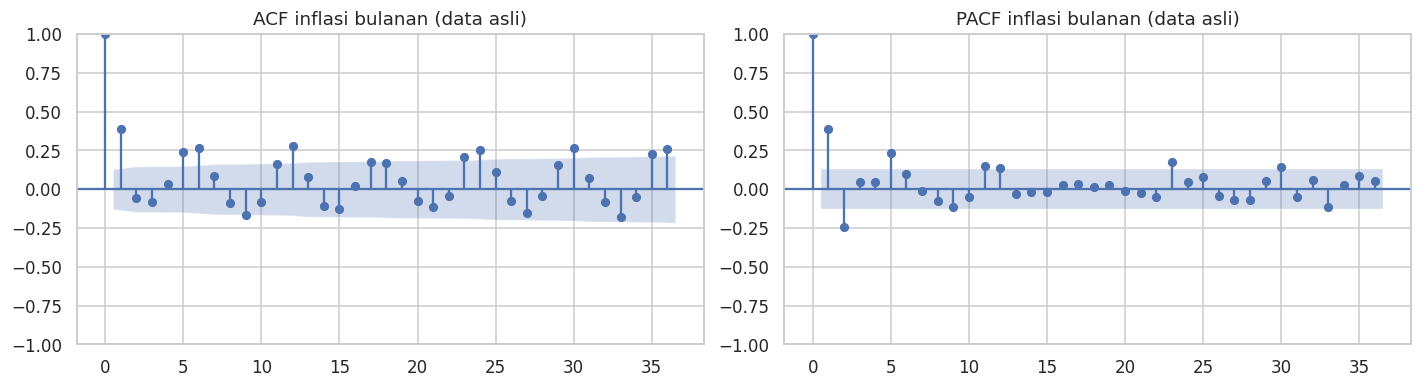

ACF  lag 1-6   : [ 0.385 -0.057 -0.083  0.031  0.239  0.264]
PACF lag 1-6   : [ 0.385 -0.24   0.046  0.048  0.233  0.096]
lag ACF signifikan  : [1, 5, 6, 9, 11, 12, 17, 18, 23, 24, 27, 29, 30, 33, 35, 36]
lag PACF signifikan : [1, 2, 5, 11, 12, 23, 30]
ACF lag 12, 24, 36  : [0.276 0.252 0.26 ]
Ljung-Box (12 lag): Q = 105.0, p = 0.0000


In [ ]:
T = len(inflasi)
print(f'T = {T} | pita 95% = ±{1.96 / np.sqrt(T):.3f}')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(inflasi, lags=36, ax=ax[0], title='ACF inflasi bulanan (data asli)')
plot_pacf(inflasi, lags=36, ax=ax[1], title='PACF inflasi bulanan (data asli)', method='ywm')
plt.tight_layout(); plt.show()

a_asli, p_asli = acf(inflasi, nlags=36), pacf(inflasi, nlags=36, method='ywm')
print('ACF  lag 1-6   :', a_asli[1:7].round(3))
print('PACF lag 1-6   :', p_asli[1:7].round(3))
print('lag ACF signifikan  :', lag_signifikan(a_asli, T))
print('lag PACF signifikan :', lag_signifikan(p_asli, T))
print('ACF lag 12, 24, 36  :', a_asli[[12, 24, 36]].round(3))
q, p = ljung_box(inflasi, 12); print(f'Ljung-Box (12 lag): Q = {q:.1f}, p = {p:.4f}')

> **Interpretasi data asli (a).** Dengan T = 231, pita 95% adalah ±0,129.
> - ACF lag 1 = 0,385 (signifikan), lag 2–4 kecil dan di dalam pita (−0,057; −0,083; 0,031), lalu kembali menonjol di lag 5 dan 6 (0,239 dan 0,264).
> - Tonjolan juga muncul di lag **12, 24, dan 36** (0,276; 0,252; 0,260) dengan tinggi yang hampir tidak meluruh. Ini ciri musiman bulanan yang ditumpangi pergeseran level, sesuai temuan Praktikum 1–3.
> - PACF besar di lag 1 (0,385) dan lag 2 (−0,240), lalu muncul lagi di lag 5, 11, dan 12.
> - Ljung-Box 12 lag: Q = 105,0 dengan p ≈ 0, jadi jelas ada ketergantungan antarbulan.
>
> Bentuk ini mirip AR(2) bila hanya dilihat dari lag 1–2, tetapi ACF yang tidak segera meluruh di lag musiman menandakan data asli belum ideal untuk identifikasi. Karena itu analisis dilanjutkan pada data yang sudah distasionerkan.


### 2.2 (b) Data yang sudah distasionerkan
Sesuai keputusan Praktikum 2, dipakai selisih biasa (d = 1) dari inflasi bulanan.

T = 230 | pita 95% = ±0.129


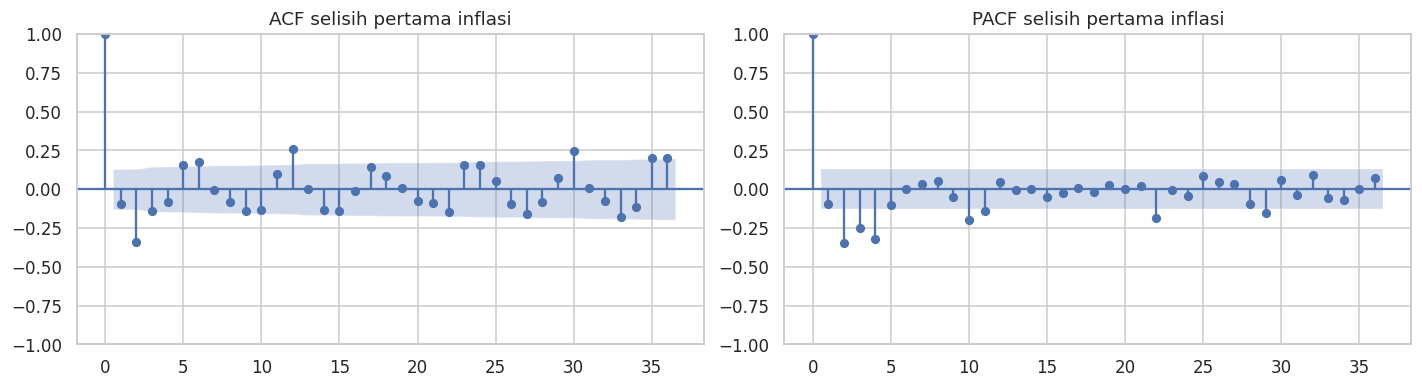

ACF  lag 1-6   : [-0.094 -0.337 -0.141 -0.082  0.157  0.177]
PACF lag 1-6   : [-0.094 -0.349 -0.249 -0.324 -0.104  0.004]
lag ACF signifikan  : [2, 3, 5, 6, 9, 10, 12, 14, 15, 17, 22, 23, 24, 27, 30, 33, 35, 36]
lag PACF signifikan : [2, 3, 4, 10, 11, 22, 29]
ACF  lag 12, 24, 36 : [0.257 0.153 0.2  ]
PACF lag 12, 24     : [ 0.049 -0.043]
lag berturut-turut dari lag 1: ACF = 0 | PACF = 0
Ljung-Box (12 lag): Q = 77.7, p = 0.0000


In [ ]:
d1 = inflasi.diff().dropna()
Td = len(d1)
print(f'T = {Td} | pita 95% = ±{1.96 / np.sqrt(Td):.3f}')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(d1, lags=36, ax=ax[0], title='ACF selisih pertama inflasi')
plot_pacf(d1, lags=36, ax=ax[1], title='PACF selisih pertama inflasi', method='ywm')
plt.tight_layout(); plt.show()

a_d, p_d = acf(d1, nlags=36), pacf(d1, nlags=36, method='ywm')
print('ACF  lag 1-6   :', a_d[1:7].round(3))
print('PACF lag 1-6   :', p_d[1:7].round(3))
print('lag ACF signifikan  :', lag_signifikan(a_d, Td))
print('lag PACF signifikan :', lag_signifikan(p_d, Td))
print('ACF  lag 12, 24, 36 :', a_d[[12, 24, 36]].round(3))
print('PACF lag 12, 24     :', p_d[[12, 24]].round(3))
print('lag berturut-turut dari lag 1: ACF =', potong(a_d, Td), '| PACF =', potong(p_d, Td))
q, p = ljung_box(d1, 12); print(f'Ljung-Box (12 lag): Q = {q:.1f}, p = {p:.4f}')

> **Interpretasi data stasioner (b), selisih pertama.** Dengan T = 230, pita 95% adalah ±0,129.
> - ACF: lag 1 hanya −0,094 (tidak signifikan), **lag 2 = −0,337 (menonjol)**, lag 3 = −0,141, lalu sebagian besar kecil. Pola ini terpotong sekitar lag 2.
> - PACF: lag 2, 3, 4 berturut-turut −0,349; −0,249; −0,324 dan lag 1 hanya −0,094. Batang PACF masih besar beberapa lag lalu mengecil, yaitu bentuk **meluruh**, bukan terpotong.
> - Pola "ACF terpotong, PACF meluruh" adalah tanda tangan **MA(2)**.
> - **Musiman:** ACF di lag 12, 24, 36 masih menonjol (0,257; 0,153; 0,200), jadi masih ada ketergantungan tahunan yang belum tertangkap. PACF di lag 12 dan 24 kecil (0,049 dan −0,043).
> - Ljung-Box 12 lag: Q = 77,7 dengan p ≈ 0, artinya data selisih ini belum white noise dan masih bisa dimodelkan.
>
> **Catatan tentang aturan otomatis.** Fungsi `potong` memberi hitungan 0 untuk ACF maupun PACF, karena lag 1 tidak signifikan walaupun lag 2 sangat menonjol. Ini contoh persis dari buku: aturan otomatis sebatas petunjuk awal, bentuk keseluruhan plot yang menentukan.


### 2.3 Pemeriksaan awal kandidat model
Bukan bagian wajib Latihan 4.1; hanya menguji secara cepat apakah kandidat dari ACF/PACF masuk akal (AIC lebih kecil = lebih baik). Pemilihan model lengkap dibahas di Bab 6.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

kandidat = [((0, 1, 1), (0, 0, 0, 0)), ((1, 1, 0), (0, 0, 0, 0)), ((1, 1, 1), (0, 0, 0, 0)),
            ((0, 1, 2), (0, 0, 0, 0)), ((2, 1, 0), (0, 0, 0, 0)), ((2, 1, 1), (0, 0, 0, 0)),
            ((0, 1, 3), (0, 0, 0, 0)),
            ((0, 1, 2), (1, 0, 0, 12)), ((0, 1, 2), (0, 0, 1, 12)), ((0, 1, 2), (1, 0, 1, 12))]
baris = []
for orde, musim in kandidat:
    hasil = ARIMA(inflasi, order=orde, seasonal_order=musim).fit()
    nama = f'ARIMA{orde}' + (f'x{musim[:3]}[12]' if musim[3] else '')
    baris.append({'model': nama, 'AIC': hasil.aic, 'BIC': hasil.bic})
tabel_kand = pd.DataFrame(baris).set_index('model').round(1).sort_values('AIC')
tabel_kand['selisih AIC'] = (tabel_kand['AIC'] - tabel_kand['AIC'].min()).round(1)
tabel_kand

,AIC,BIC,selisih AIC
model,,,
"ARIMA(0, 1, 2)x(1, 0, 1)[12]",260.3,277.5,0.0
"ARIMA(0, 1, 2)x(1, 0, 0)[12]",267.6,281.3,7.3
"ARIMA(0, 1, 2)x(0, 0, 1)[12]",269.7,283.4,9.4
"ARIMA(2, 1, 1)",274.8,288.5,14.5
"ARIMA(0, 1, 2)",277.7,288.1,17.4
"ARIMA(0, 1, 3)",279.4,293.2,19.1
"ARIMA(1, 1, 1)",295.1,305.4,34.8
"ARIMA(0, 1, 1)",323.2,330.1,62.9
"ARIMA(2, 1, 0)",336.0,346.3,75.7


### Jawaban Latihan 4.1 — kandidat model dan alasan

| Kandidat | Alasan dari ACF/PACF | AIC | BIC |
|---|---|---|---|
| **ARIMA(0,1,2)** | ACF terpotong di lag 2 (−0,337), PACF meluruh (lag 2–4 sebesar −0,35; −0,25; −0,32) → MA(2) | 277,7 | **288,1** |
| ARIMA(2,1,1) | Alternatif bila ada komponen AR; AIC sedikit lebih kecil, tetapi parameter lebih banyak dan BIC sedikit lebih besar | 274,8 | 288,5 |
| ARIMA(0,1,3) | Lag 3 di ACF (−0,141) mepet pita, tetapi AIC tidak membaik | 279,4 | 293,2 |
| **ARIMA(0,1,2)(1,0,1)₁₂** | Ditambah komponen musiman karena ACF menonjol di lag 12, 24, 36; selisih musiman tidak dipakai (Praktikum 2) sehingga D = 0 | **260,3** | **277,5** |

> **Interpretasi.**
> - Untuk bagian non-musiman, kandidat utamanya **ARIMA(0,1,2)**, sesuai pola ACF terpotong di lag 2 dan PACF meluruh.
> - Menambah komponen musiman memperbaiki model dengan nyata: AIC turun dari 277,7 ke 260,3 (selisih 17,4) dan BIC dari 288,1 ke 277,5 (selisih 10,6). Jadi musiman ringan di data inflasi memang layak dimodelkan, walaupun lemah secara visual.
> - Kandidat dengan hanya AR (ARIMA(1,1,0) AIC 367,3 dan ARIMA(2,1,0) AIC 336,0) jauh lebih buruk, sehingga struktur MA memang yang dominan.
> - Ini baru pemeriksaan awal. Pemilihan akhir memakai AICc serta diagnostik residu di Bab 6 dan Bab 10.


## 3. Latihan 4.2 — Tebak prosesnya
Kode pembangkit tiga deret misteri diambil dari soal. Tebakan dibuat **hanya dari plot ACF/PACF**; kunci jawaban dicocokkan setelahnya.

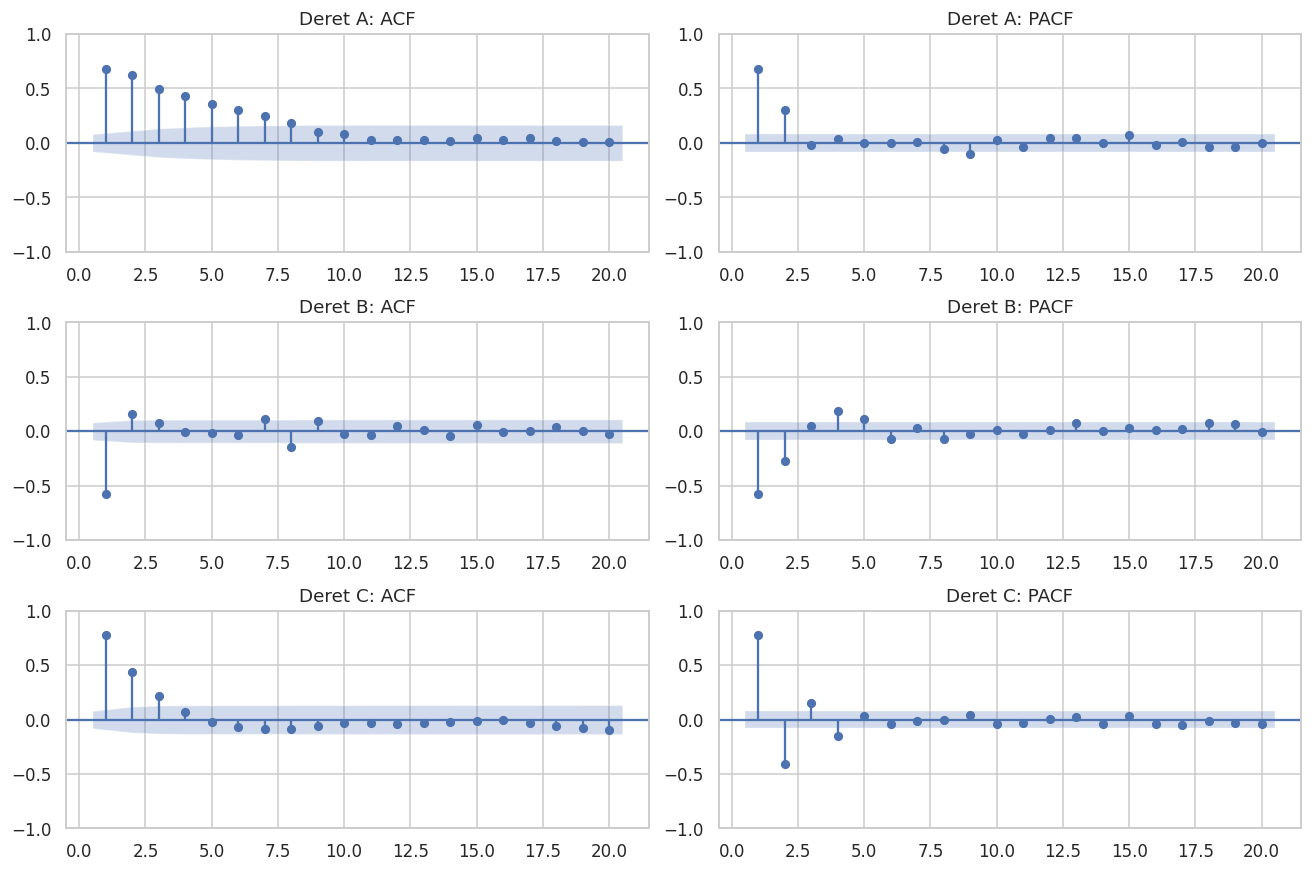

Deret A
  ACF  lag 1-6 : [0.68 0.62 0.49 0.43 0.35 0.3 ] | lag signifikan: [1, 2, 3, 4, 5, 6, 7, 8, 9]
  PACF lag 1-6 : [ 0.68  0.3  -0.02  0.03 -0.   -0.01] | lag signifikan: [1, 2, 9]
Deret B
  ACF  lag 1-6 : [-0.58  0.16  0.07 -0.01 -0.02 -0.03] | lag signifikan: [1, 2, 7, 8, 9]
  PACF lag 1-6 : [-0.58 -0.27  0.05  0.18  0.11 -0.07] | lag signifikan: [1, 2, 4, 5]
Deret C
  ACF  lag 1-6 : [ 0.78  0.44  0.22  0.07 -0.03 -0.07] | lag signifikan: [1, 2, 3, 7, 8]
  PACF lag 1-6 : [ 0.78 -0.4   0.15 -0.15  0.03 -0.04] | lag signifikan: [1, 2, 3, 4]


In [ ]:
misteri = {k: ArmaProcess(ar, ma).generate_sample(600, distrvs=np.random.default_rng(i).standard_normal)
           for i, (k, ar, ma) in enumerate([('A', [1, -0.5, -0.3], [1]),
                                            ('B', [1], [1, -0.7, 0.4]),
                                            ('C', [1, -0.6], [1, 0.6])])}
fig, axs = plt.subplots(3, 2, figsize=(12, 8))
for i, (k, y) in enumerate(misteri.items()):
    plot_acf(y, lags=20, ax=axs[i, 0], title=f'Deret {k}: ACF', zero=False)
    plot_pacf(y, lags=20, ax=axs[i, 1], title=f'Deret {k}: PACF', zero=False, method='ywm')
plt.tight_layout(); plt.show()

Tm = 600
for k, y in misteri.items():
    a, p = acf(y, nlags=10), pacf(y, nlags=10, method='ywm')
    print(f'Deret {k}')
    print('  ACF  lag 1-6 :', a[1:7].round(2), '| lag signifikan:', lag_signifikan(a, Tm))
    print('  PACF lag 1-6 :', p[1:7].round(2), '| lag signifikan:', lag_signifikan(p, Tm))

### Jawaban Latihan 4.2 — tebakan dari ACF/PACF saja

| Deret | Pola ACF | Pola PACF | Tebakan |
|---|---|---|---|
| A | Meluruh perlahan (0,68; 0,62; 0,49; 0,43; 0,35; 0,30) | Dua batang besar (0,68; 0,30), lalu mendekati nol (lag 3 = −0,02) | **AR(2)** |
| B | Hanya lag 1 (−0,58) dan lag 2 (0,16) yang menonjol, lalu mendekati nol | −0,58; −0,27, lalu mengecil dengan tanda bergantian | **MA(2)** |
| C | Meluruh dari 0,78 (0,78; 0,44; 0,22; 0,07) | Meluruh dengan tanda bergantian (0,78; −0,40; 0,15; −0,15) | **ARMA(1,1)** |

> **Alasan.** Pada A, PACF terpotong di lag 2 sementara ACF meluruh, tanda tangan AR(2). Pada B, ACF terpotong di lag 2 sementara PACF meluruh, tanda tangan MA(2). Pada C, kedua fungsi meluruh tanpa pemotongan yang jelas, tanda tangan ARMA. Beberapa batang kecil yang melewati pita pada lag jauh (misalnya lag 9 di deret A) hanyalah kebetulan, karena dari 20 lag rata-rata satu batang menembus pita 95%.


In [ ]:
# Kunci: cocokkan tebakan dengan model sebenarnya lewat estimasi parameter
from statsmodels.tsa.arima.model import ARIMA
cek = {'A': (2, 0, 0), 'B': (0, 0, 2), 'C': (1, 0, 1)}
asli = {'A': 'AR(2): phi = (0,5; 0,3)', 'B': 'MA(2): theta = (-0,7; 0,4)', 'C': 'ARMA(1,1): phi = 0,6; theta = 0,6'}
for k, orde in cek.items():
    hasil = ARIMA(misteri[k], order=orde, trend='n').fit()
    print(f'Deret {k}: {asli[k]:<36} | estimasi: ' + ', '.join(f'{n}={v:.2f}' for n, v in zip(hasil.param_names, hasil.params)))

Deret A: AR(2): phi = (0,5; 0,3)              | estimasi: ar.L1=0.47, ar.L2=0.31, sigma2=0.99
Deret B: MA(2): theta = (-0,7; 0,4)           | estimasi: ma.L1=-0.78, ma.L2=0.43, sigma2=0.89
Deret C: ARMA(1,1): phi = 0,6; theta = 0,6    | estimasi: ar.L1=0.60, ma.L1=0.59, sigma2=1.00


> **Kunci jawaban.** Tebakan ketiganya cocok dengan model pembangkitnya: A = AR(2) dengan φ = (0,5; 0,3), B = MA(2) dengan θ = (−0,7; 0,4), dan C = ARMA(1,1) dengan φ = 0,6 dan θ = 0,6. Estimasi parameter dari data (A: 0,47 dan 0,31; B: −0,78 dan 0,43; C: 0,60 dan 0,59) sangat dekat dengan nilai sebenarnya, dengan selisih kecil akibat variasi sampel (n = 600).


## 4. Latihan 4.3 — Ljung-Box pada kelahiran harian

simpangan baku: 7.35 | ACF lag 1: 0.218 | pita 95%: ± 0.103
      lb_stat lb_pvalue  Q (hitung sendiri)
5   36.801412  6.56e-07           36.801412
10  63.880949  6.63e-10           63.880949
20  81.745126  1.98e-09           81.745126
lag ACF signifikan (1-30): [1, 2, 3, 7, 8, 15, 21, 22, 27, 28, 29, 30]
ACF lag 1-8 : [0.217 0.153 0.108 0.091 0.096 0.091 0.195 0.141]


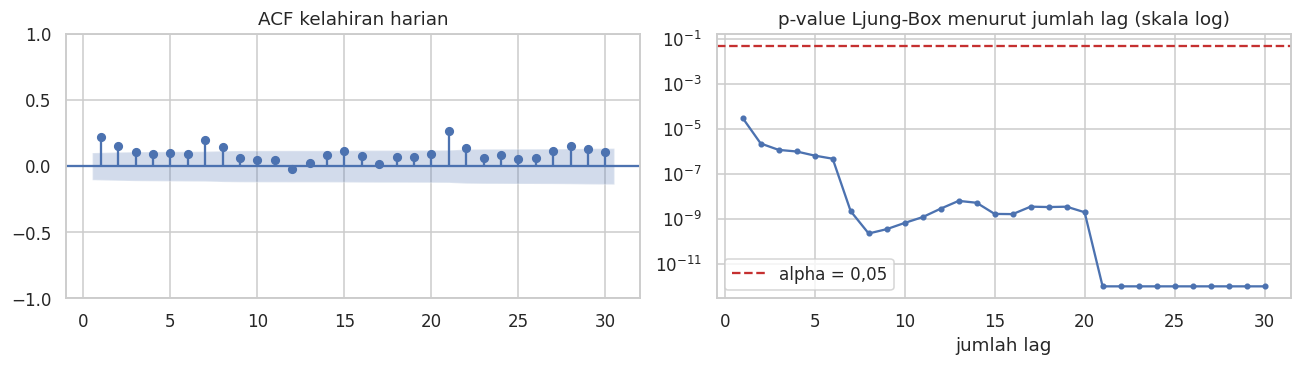

p-value terkecil / terbesar untuk lag 1-30: 8.97e-18 / 3.08e-05
lag Ljung-Box yang tidak menolak H0 (p >= 0,05): []


In [ ]:
print('simpangan baku:', round(lahir.std(), 2), '| ACF lag 1:', round(lahir.autocorr(1), 3), '| pita 95%: ±', round(1.96 / np.sqrt(len(lahir)), 3))
lb = acorr_ljungbox(lahir, lags=[5, 10, 20])
lb['Q (hitung sendiri)'] = [ljung_box(lahir, h)[0] for h in [5, 10, 20]]
lb_tampil = lb.copy(); lb_tampil['lb_pvalue'] = lb_tampil['lb_pvalue'].map('{:.2e}'.format)
print(lb_tampil)

a_l = acf(lahir, nlags=30)
print('lag ACF signifikan (1-30):', lag_signifikan(a_l, len(lahir)))
print('ACF lag 1-8 :', a_l[1:9].round(3))

semua = acorr_ljungbox(lahir, lags=range(1, 31))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
plot_acf(lahir, lags=30, ax=ax[0], title='ACF kelahiran harian', zero=False)
ax[1].semilogy(semua.index, semua['lb_pvalue'].clip(lower=1e-12), marker='o', ms=3)
ax[1].axhline(0.05, color='#c53030', ls='--', label='alpha = 0,05'); ax[1].legend()
ax[1].set_title('p-value Ljung-Box menurut jumlah lag (skala log)'); ax[1].set_xlabel('jumlah lag')
plt.tight_layout(); plt.show()
print('p-value terkecil / terbesar untuk lag 1-30:', f"{semua['lb_pvalue'].min():.2e}", '/', f"{semua['lb_pvalue'].max():.2e}")
print('lag Ljung-Box yang tidak menolak H0 (p >= 0,05):', semua.index[semua['lb_pvalue'] >= 0.05].tolist())

### Jawaban Latihan 4.3

| Jumlah lag | Statistik Q | p-value | Keputusan (α = 0,05) |
|---|---|---|---|
| 5 | 36,80 | 6,56 × 10⁻⁷ | tolak H₀ |
| 10 | 63,88 | 6,63 × 10⁻¹⁰ | tolak H₀ |
| 20 | 81,75 | 1,98 × 10⁻⁹ | tolak H₀ |

> **Interpretasi.** Kesimpulannya **tidak berubah** dengan jumlah lag: pada ketiga pilihan, H₀ (tidak ada autokorelasi) ditolak dengan p-value jauh di bawah 0,05. Bahkan bila diuji untuk setiap jumlah lag dari 1 sampai 30, p-value terbesarnya hanya 3,08 × 10⁻⁵, dan tidak ada satu pun yang gagal menolak H₀.
>
> Setiap batang ACF sebenarnya kecil: lag 1 = 0,217, lag 2 = 0,153, lag 3 = 0,108 (pita ±0,103), tetapi nilainya konsisten positif dan meluruh sehingga akumulasi evidensinya kuat, sesuai prinsip Ljung-Box yang menjumlahkan banyak lag sekaligus. Ada juga tonjolan di lag 7 (0,195) yang mungkin mengisyaratkan pola mingguan, tetapi ini baru dugaan dan perlu diperiksa lebih lanjut, misalnya bersama kemungkinan tren atau pergeseran level. Jadi kelahiran harian **bukan white noise**: masih ada dependensi kecil yang bisa dimodelkan.


## Kesimpulan

1. ACF, PACF, dan Ljung-Box buatan sendiri identik dengan statsmodels, sehingga hasil hitungan bisa dipercaya.
2. Pada data asli inflasi, ACF memperlihatkan ketergantungan musiman (lag 12, 24, 36) yang bercampur dengan pergeseran level, jadi identifikasi model dilakukan pada selisih pertama.
3. Selisih pertama inflasi menunjukkan ACF terpotong di lag 2 dan PACF meluruh, yaitu pola **MA(2)**, ditambah tonjolan musiman di lag 12. Kandidat utama **ARIMA(0,1,2)**, dan penambahan komponen musiman (ARIMA(0,1,2)(1,0,1)₁₂) menurunkan AIC dari 277,7 ke 260,3.
4. Tiga deret misteri berhasil ditebak dari ACF/PACF saja: A = AR(2), B = MA(2), C = ARMA(1,1).
5. Ljung-Box pada kelahiran harian menolak white noise untuk lag 5, 10, 20 (bahkan untuk semua lag 1–30), sehingga kesimpulannya tidak bergantung pada jumlah lag.
6. Aturan "hitung lag berturut-turut" hanyalah petunjuk awal, karena bisa gagal (misalnya pada selisih inflasi). Bentuk keseluruhan plot dan kriteria AIC/BIC harus dipakai bersama.
